In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve().parent

TRAIN_PATH = (
    PROJECT_ROOT
    / "data/processed/technical/de-en/train.csv"
)

df = pd.read_csv(TRAIN_PATH)

print("Dataset shape:", df.shape)
display(df.head(10))


Dataset shape: (102205, 2)


,source,target
0,The Babel & konqueror; plugin gives you quick ...,Mit Hilfe des & konqueror;-Modul Babel haben S...
1,The Babel & konqueror; plugin,Das & konqueror;-Modul Babel
2,Babelfish is a machine translation service pro...,Babelfish ist ein von AltaVista bereitgestellt...
3,The plugin allows you to automatically transla...,Das Modul erlaubt die automatische Übersetzung...
4,The Babelfish plugin can be accessed in the & ...,Das Modul Webseite übersetzen finden Sie im & ...
5,If you have a portion of the text on the page ...,"Falls ein Teil des Textes ausgewählt ist, wird..."
6,Not all languages are available from the Babel...,Der Babelfish-Dienst ist nicht für alle Sprach...
7,Machine translation is not a perfect science! ...,Maschinelle Übersetzungen sind nur sehr rudime...
8,You may only translate web pages that are acce...,Nur Webseiten im Internet können übersetzt wer...
9,The Babelfish plugin is copyright (C) 2001 & K...,Das Babelfish-Modul steht unter dem Copyright ...


In [2]:
# Check for missing values and duplicates


print("Missing values:")
display(df.isna().sum())

print("Exact duplicate pairs:", df.duplicated().sum())
print("Duplicate sources:", df["source"].duplicated().sum())
print("Duplicate targets:", df["target"].duplicated().sum())

Missing values:


source    0
target    0
dtype: int64

Exact duplicate pairs: 0
Duplicate sources: 4293
Duplicate targets: 4639


In [12]:
# Inspect random translations
import pandas as pd

# Display full text without truncation
pd.set_option("display.max_colwidth", None)

SAMPLE_SIZE = 30
SEED = 66

sample = df.sample(
    n=min(SAMPLE_SIZE, len(df)),
    random_state=SEED
)

display(sample[["source", "target"]])

,source,target
12476,"This module is a configuration tool for managing Power Management in & kde;. It is a configurator for the PowerDevil daemon, that you can start or stop from the Service Manager module.","Dieses Modul erlaubt die Einrichtung der Energieverwaltung für & kde;. Damit wird der PowerDevil-Dienst eingestellt, der im Modul Diensteverwaltung gestartet oder gestoppt werden kann."
32760,"Choose from the various game engines (Open Board, FIBS, & GNU; Backgammon, Next Generation) here.","Hier können Sie die verschiedenen Spielprogramme auswählen (Offenes Brett, FIBS, & GNU;-Backgammon (experimentell), Nächste Generation (experimentell))."
30926,"If you prefer to check spelling explicitly, rather than automatically, you can also force a Spelling... check here.","Falls Sie Rechtschreibprüfung lieber manuell aufrufen wollen, können Sie eine Rechtschreibprüfung... mit diesem Menüeintrag starten."
69496,"What font to use for the panel at the bottom of the screen, where the currently running applications are.","Die Schrift, die von der Programmleiste in der Kontrollleiste verwendet wird."
53297,Unknown Device,Unbekanntes Gerät
47156,Modify original input files,Ursprüngliche Eingabedatei bearbeiten
40676,Lower limit on the video contrast,Legt eine Untergrenze für den Kontrast der Videowiedergabe fest
44696,"The argument to \\bibliographystyle refers to a file style. bst, which defines how your citations will look The standard styles distributed with BibTeX are: alpha: sorted alphabetically. Labels are formed from name of author and year of publication. plain: sorted alphabetically. Labels are numeric. unsrt: like plain, but entries are in order of citation. abbrv: like plain, but more compact labels.","Das Argument zu \\bibliographystyle bezieht sich auf eine Datei"" style.bst"", die definiert, wie Ihre Literaturangaben aussehen. Die Standardstile von BibTeX sind: \talpha:\tAlphabetisch sortiert; die Label bestehen aus dem Namen des Autors und dem Jahr der Veröffentlichung. \tplain:\tAlphabetisch sortiert; die Label sind Zahlen. \tunsrt:\tWie plain, aber die Einträge bleiben in der Reihenfolge der Erwähnung. \tabbrv:\tWie plain, aber mit kompakteren Label."
62415,Hide constellation boundaries while moving?,Sternbildgrenzen bei Bewegung ausblenden?
77171,Mark Message as & Action Item,Nachricht als & Aufgabe markieren


,source_words,target_words,length_ratio
count,102205.000000,102205.000000,102205.000000
mean,11.197280,10.704584,1.071226
std,14.999059,13.860779,0.777345
min,2.000000,2.000000,0.021739
25%,3.000000,3.000000,0.826923
50%,5.000000,5.000000,1.000000
75%,12.000000,12.000000,1.090909
max,100.000000,100.000000,40.000000


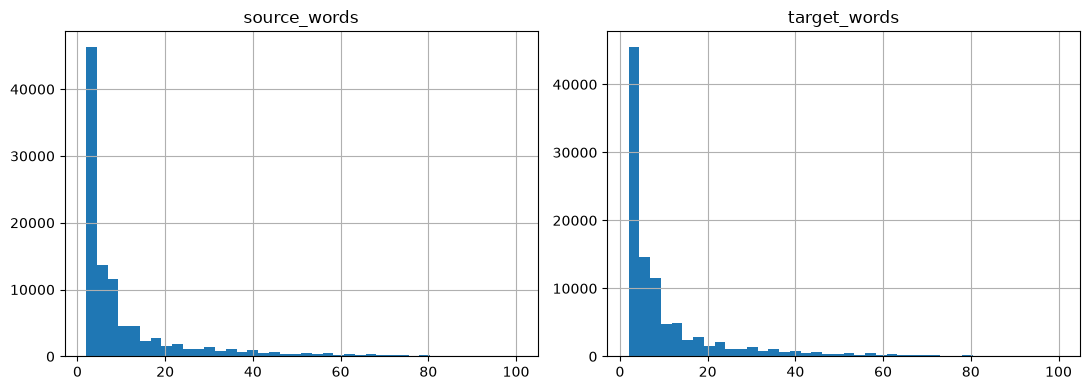

In [13]:
#Analyze sentence lengths

df["source_words"] = df["source"].str.split().str.len()
df["target_words"] = df["target"].str.split().str.len()

df["length_ratio"] = (
    df["target_words"] / df["source_words"].clip(lower=1)
)

display(
    df[["source_words", "target_words", "length_ratio"]]
    .describe()
)

df[["source_words", "target_words"]].hist(
    bins=40,
    figsize=(11, 4)
)

plt.tight_layout()
plt.show()


In [17]:
# inspect the extreme differences
suspicious_lengths = df[
    (df["length_ratio"] < 0.2) |
    (df["length_ratio"] > 2.5)
]

print("Suspicious length ratios:", len(suspicious_lengths))

display(
    suspicious_lengths[
        ["source", "target", "length_ratio"]
    ].head(30)
)


Suspicious length ratios: 1951


,source,target,length_ratio
473,"tag, comment, geo-locate","Fügen Sie Stichwörter, Kommentare und die geografische Lokalisierung hinzu.",3.000000
2790,Toggle the Playlist-window.,Zeigt das Wiedergabelisten-Fenster an bzw. blendet es aus.,2.666667
3239,Ctrl; D Playlist,Strg D Wiedergabeliste Ausgewählte Stücke in Warteschlange einstellen,2.666667
3777,Frequently Asked Questions (FAQ),"Bei Problemen wenden Sie sich an eine der KDE-Mailinglisten, eine Newsgruppe oder direkt an mich. Beachten Sie auch die FAQ auf der nächsten Seite, und durchsuchen Sie die Newsgruppen oder Archive der Mailinglisten, bevor Sie weitere Fragen stellen.",9.500000
3942,Toggle the statusbar.,Zeigt die Statusleiste an bzw. blendet sie aus.,2.666667
3952,Source: http: / /tlc. nlm. nih. gov/ resources/ tutorials/ internetdistlrn/ gophrdef. htm,Quelle: http://tlc.nlm.nih.gov/resources/tutorials/internetdistlrn/gophrdef.htm,0.166667
4063,scriptsize: very small.,Sehr klein (wie Indizes): Eine sehr kleine Schriftgröße.,2.666667
5719,Caseinsensitive Diff,Diff ohne Beachtung der Groß- / Kleinschreibung,3.500000
5891,"The merge-editor below the diff-windows allows you to solve conflicts, while showing you the output you will get.","Beachten Sie die Knöpfe zur Auswahl der Quelle mit der Beschriftung A, B und C unterhalb der Menüleiste. Wenn Sie auf einen der Knöpfe klicken, werden die Zeilen aus dem entsprechenden Fenster an das Ende der ausgewählten Gruppe im Ergebnisfenster angehängt (wenn sie nicht bereits vorhanden sind). Falls die Zeilen bereits vorhanden sind, werden sie beim Klicken auf den Knopf entsprechend wieder entfernt.",3.500000
5892,You can even edit the output.,"Hinweis: Sie können auch jede Zeile manuell bearbeiten. Die Zusammenfassungs-Spalte zeigt dann ein m in jeder Zeile, die Sie von Hand bearbeitet haben.",3.833333


In [19]:
# detect new metadata contamination patterns 
patterns = {
    "KDE metadata": r"@[A-Za-z]+:",
    "XML or HTML tags": r"</?[A-Za-z][^>]*>",
    "File extensions": r"\.(?:kgm|desktop|ui|xml)\b",
    "Email addresses": r"[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}",
    "Multiple spaces": r" {3,}",
    "Mojibake": r"Ã.|Â.",
}

for name, pattern in patterns.items():
    mask = df["target"].str.contains(
        pattern,
        regex=True,
        case=False,
        na=False
    )

    print(f"{name}: {mask.sum():,} matches")

    display(
        df.loc[mask, ["source", "target"]].head(5)
    )


KDE metadata: 652 matches


,source,target
6271,ftp: / / username@proxyusername: password@proxipassword@hostname/ directory,ftp: / / username@proxyusername:password@proxipassword@hostname/directory
31937,kurt@transmeta: ~ > tail / var/ log/ cups/ error_log I [04/ Aug/ 2001:23:15:10 +0100] Job 213 queued on'DANKA_P450 'by'root' I [04/ Aug/ 2001:23:15:10 +0100] Started filter / usr/ lib/ cups/ filter/ pstops (PID 18891) for job 213. I [04/ Aug/ 2001:23:15:10 +0100] Started backend / usr/ lib/ cups/ backend/ lpd (PID 18892) for job 213.,kurt@transmeta:~ > tail /var/log/cups/error_log I [04/Aug/2001:23:15:10 +0100] Job 213 queued on 'DANKA_P450' by 'root' I [04/Aug/2001:23:15:10 +0100] Started filter /usr/lib/cups/filter/pstops (PID 18891) for job 213. I [04/Aug/2001:23:15:10 +0100] Started backend /usr/lib/cups/backend/lpd (PID 18892) for job 213.
34156,Opens the help browser with the FSView documentation,Öffnet das Hilfeprogramm mit der FSView-Dokumentation@action:inmenu File
34157,& Edit File Type...,Dateityp bearbeiten ...@action:inmenu File
34823,Add to Existing Queue,An vorhandene Warteschlange anhängen@action:inmenu Pluralized


XML or HTML tags: 0 matches


,source,target


File extensions: 136 matches


...

,source,target
34,The dirfilter plugin is copyright & copy; 2000-2002 Dawit Alemayehu adawit@kde. org.,Das Modul Ordnerfilter ist Copyright & copy; 2000-2002 Dawit Alemayehu adawit@kde.org.
39,The domtreeviewer plugin is Copyright & copy; 2001 The Kafka Team/ Andreas Schlapbach kde-kafka@master. kde. org schlpbch@unibe. ch,Das Modul DOM-Baumansicht ist Copyright & copy; 2001 The Kafka Team/Andreas Schlapbach kde-kafka@master.kde.org schlpbch@unibe.ch
40,Josef Weidendorfer Josef. Weidendorfer@gmx. de,Josef Weidendorfer Josef.Weidendorfer@gmx.de
93,Andreas Schlapbach schlpbch@iam. unibe. ch,Andreas Schlapbach schlpbch@iam.unibe.ch
94,Documentation Copyright 2004 Mike Diehl madpenguin8@yahoo. com,Dokumentation Copyright 2004 Mike Diehl madpenguin8@yahoo.com


Multiple spaces: 0 matches


,source,target


Mojibake: 10 matches


,source,target
14158,Brazilian Portuguese data files: João Sebastião de Oliveira Bueno gwidion@mpc. com. br,Brasilianisches Portugiesische Datendateien: João Sebastião de Oliveira Bueno gwidion@mpc.com.br
34359,Aurélien Gâteau,Aurélien GâteauName
34563,Sao Tome and Principe,São Tomé und Príncipe
47306,"Â(#194;) Capital A, circumflex accent",Â(#194;) A mit Zirkumflex
47330,"â (#226;) Small a, circumflex accent",â (#226;) a mit Zirkumflex
